# 02 · Piloto do pré-processamento

Testa, em cinco alvos, o pré-processamento baseado em Shallue e Vanderburg (2018): download do fluxo PDCSAP, remoção de *outliers*, achatamento com máscara de trânsito, *phase-folding* e construção das Visões Global e Local. O objetivo é verificar visualmente que o trânsito sobrevive a todas as etapas antes de processar os 6.695 KOIs no notebook 03.

Não precisa de GPU.

## 1. Instalação

O `lightkurve` não vem instalado no Colab. A versão é fixada em 2.6.0, a mesma usada no restante do trabalho.

In [1]:
!pip install -q lightkurve==2.6.0

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk
from scipy.stats import binned_statistic

print('lightkurve:', lk.__version__)

lightkurve: 2.6.0


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## 2. Parâmetros

- `SIGMA_OUTLIER = 6`: remove apenas os pontos mais de 6 desvios-padrão **acima** da mediana (`sigma_lower=inf`), o que preserva o fundo dos trânsitos profundos. Na primeira rodada do experimento, o corte era feito dos dois lados (ver notebook 10);
- `GLOBAL_BINS = 2001` e `LOCAL_BINS = 201`: tamanhos das visões, como no Astronet;
- `K_DURATIONS = 4`: a Visão Local cobre ±4 durações de trânsito.

In [3]:
SIGMA_OUTLIER = 6.0      # remove so pontos ACIMA de 6 sigma (sigma_lower=inf preserva o fundo dos transitos)
GLOBAL_BINS   = 2001     # Visao Global (Astronet)
LOCAL_BINS    = 201      # Visao Local (Astronet)
K_DURATIONS   = 4        # Visao Local cobre +-K duracoes de transito
N_PILOTO      = 5        # numero de alvos do piloto

DATA_DIR = '/content/drive/MyDrive/TCC-Exoplanetas'  # onde esta koi_labels.csv

## 3. Escolha dos alvos

Três planetas confirmados e dois falsos positivos com o maior SNR, cujos sinais fortes facilitam a inspeção visual. Se `koi_labels.csv` não estiver no Drive, a célula o gera de novo a partir do TAP.

In [4]:
import os, io, urllib.parse, requests
from google.colab import drive
drive.mount('/content/drive')

# Garante a pasta e o CSV. Se o koi_labels.csv nao estiver no Drive
# (ex.: Notebook 01 nao foi salvo la), regenera direto do TAP.
os.makedirs(DATA_DIR, exist_ok=True)
csv_path = f'{DATA_DIR}/koi_labels.csv'

if not os.path.exists(csv_path):
    print('CSV nao encontrado no Drive — regerando via TAP...')
    ADQL = """SELECT kepid, kepoi_name, kepler_name, koi_disposition, koi_pdisposition,
              koi_period, koi_time0bk, koi_duration, koi_depth, koi_prad,
              koi_model_snr, koi_score, koi_steff, koi_srad FROM q1_q17_dr25_koi"""
    url = 'https://exoplanetarchive.ipac.caltech.edu/TAP/sync?' + \
          urllib.parse.urlencode({'query': ADQL, 'format': 'csv'})
    df = pd.read_csv(io.StringIO(requests.get(url, timeout=120).text))
    m = df.koi_disposition.isin(['CONFIRMED', 'FALSE POSITIVE'])
    p = df[['koi_period', 'koi_time0bk', 'koi_duration']].notna().all(axis=1)
    df = df[m & p].copy()
    df['label'] = (df.koi_disposition == 'CONFIRMED').astype(int)
    df.to_csv(csv_path, index=False)
    print('Regerado:', len(df), 'linhas')
else:
    print('CSV encontrado:', csv_path)

labels = pd.read_csv(csv_path)
print('KOIs no CSV:', len(labels))

conf = labels[labels.label == 1].sort_values('koi_model_snr', ascending=False).head(3)
fp   = labels[labels.label == 0].sort_values('koi_model_snr', ascending=False).head(2)
piloto = pd.concat([conf, fp]).reset_index(drop=True)
piloto[['kepid', 'kepoi_name', 'kepler_name', 'koi_disposition',
        'koi_period', 'koi_time0bk', 'koi_duration', 'koi_model_snr']]

Mounted at /content/drive
CSV encontrado: /content/drive/MyDrive/TCC-Exoplanetas/koi_labels.csv
KOIs no CSV: 6695


,kepid,kepoi_name,kepler_name,koi_disposition,koi_period,koi_time0bk,koi_duration,koi_model_snr
0,10666592,K00002.01,Kepler-2 b,CONFIRMED,2.204735,121.358542,3.88864,5945.9
1,11446443,K00001.01,Kepler-1 b,CONFIRMED,2.470613,122.763305,1.74319,4304.3
2,9941662,K00013.01,Kepler-13 b,CONFIRMED,1.763588,120.565925,3.16877,4061.9
3,7970760,K06943.01,NaN,FALSE POSITIVE,7.649413,132.107052,6.56935,9054.7
4,10191056,K05774.01,NaN,FALSE POSITIVE,1.213747,131.742310,5.79293,8755.2


## 4. Funções auxiliares

`median_bin` calcula a mediana dos pontos em cada bin e preenche os bins vazios por interpolação linear, como no Astronet. `normalize_view` leva a mediana a 0 e o mínimo a −1.

In [5]:
def median_bin(x, y, num_bins, x_min, x_max):
    """Mediana por bin em [x_min, x_max]; bins vazios interpolados linearmente."""
    stat, edges, _ = binned_statistic(
        x, y, statistic='median', bins=num_bins, range=(x_min, x_max))
    centers = 0.5 * (edges[:-1] + edges[1:])
    nans = np.isnan(stat)
    if nans.all():
        return stat  # sem pontos na janela
    if nans.any():
        stat[nans] = np.interp(centers[nans], centers[~nans], stat[~nans])
    return stat


def normalize_view(v):
    """Mediana -> 0 e minimo -> -1 (Shallue & Vanderburg 2018)."""
    v = v - np.median(v)
    depth = np.abs(np.min(v))
    return v / depth if depth > 0 else v

## 5. Processamento de cada alvo

Para cada KOI: download das curvas PDCSAP de cadência longa de todos os trimestres, concatenação, remoção de NaNs e de *outliers*, achatamento com os trânsitos mascarados, *phase-folding* e construção das duas visões. Os produtos intermediários são guardados para os gráficos.

In [6]:
def processar_alvo(row):
    kepid    = int(row.kepid)
    period   = float(row.koi_period)        # dias
    t0       = float(row.koi_time0bk)        # BKJD
    dur_days = float(row.koi_duration) / 24.0  # horas -> dias

    # 1) Download PDCSAP, cadencia longa, todos os quarteis
    search = lk.search_lightcurve(f'KIC {kepid}', mission='Kepler', author='Kepler', cadence='long')
    if len(search) == 0:
        print(f'  [ignorado] sem curvas para KIC {kepid}')
        return None
    lcc = search.download_all(flux_column='pdcsap_flux')
    lc = lcc.stitch().remove_nans()

    # 2) Remocao de outliers
    lc = lc.remove_outliers(sigma=SIGMA_OUTLIER, sigma_lower=np.inf)

    # 3) Flatten protegendo os transitos (mascara)
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=dur_days)
    flat = lc.flatten(window_length=901, mask=mask)

    # 4) Phase-folding (transito centrado em fase 0)
    folded = flat.fold(period=period, epoch_time=t0)
    phase = np.asarray(folded.phase.value)   # dias
    flux  = np.asarray(folded.flux.value)
    ok = np.isfinite(phase) & np.isfinite(flux)
    phase, flux = phase[ok], flux[ok]

    # 5) Visoes
    g = normalize_view(median_bin(phase, flux, GLOBAL_BINS, -period / 2, period / 2))
    half_local = min(K_DURATIONS * dur_days, period / 2)
    l = normalize_view(median_bin(phase, flux, LOCAL_BINS, -half_local, half_local))

    return dict(row=row, lc=lc, flat=flat, phase=phase, flux=flux,
                global_view=g, local_view=l, half_local=half_local)

In [7]:
resultados = []
for _, row in piloto.iterrows():
    nome = row.kepoi_name
    print(f'Processando {nome} (KIC {int(row.kepid)}, {row.koi_disposition})...')
    try:
        r = processar_alvo(row)
        if r is not None:
            resultados.append(r)
    except Exception as e:
        print(f'  [erro] {nome}: {e}')
print(f'\nConcluidos: {len(resultados)}/{len(piloto)}')

Processando K00002.01 (KIC 10666592, CONFIRMED)...
Processando K00001.01 (KIC 11446443, CONFIRMED)...
Processando K00013.01 (KIC 9941662, CONFIRMED)...
Processando K06943.01 (KIC 7970760, FALSE POSITIVE)...
Processando K05774.01 (KIC 10191056, FALSE POSITIVE)...

Concluidos: 5/5


## 6. Inspeção visual

Para cada alvo: a curva dobrada em fase, ampliada perto do trânsito, a Visão Global e a Visão Local. Nos planetas confirmados, espera-se um trânsito nítido e centrado; nos falsos positivos, formas atípicas, como trânsito em V, eclipse secundário ou variação senoidal.

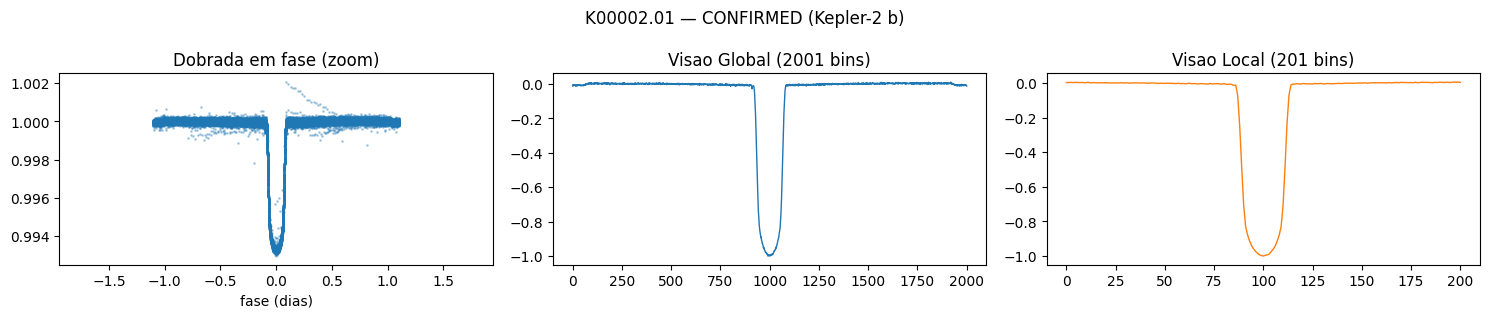

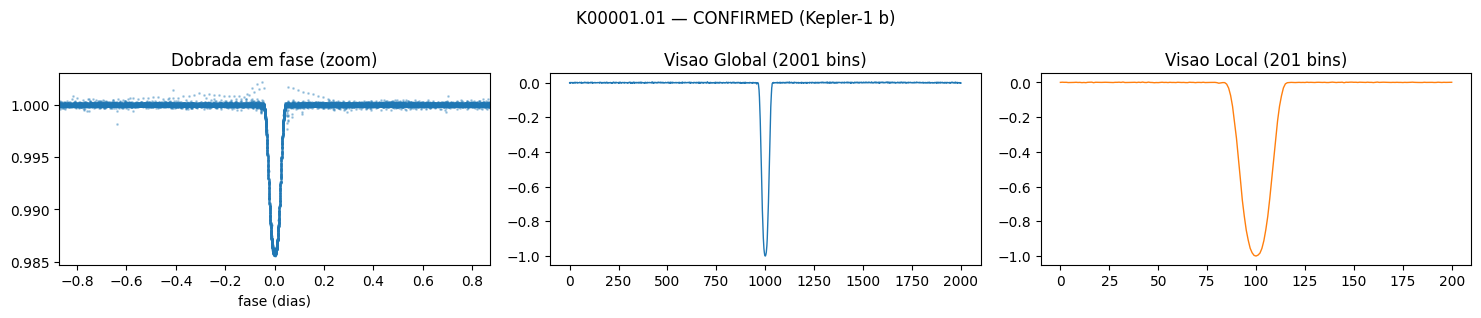

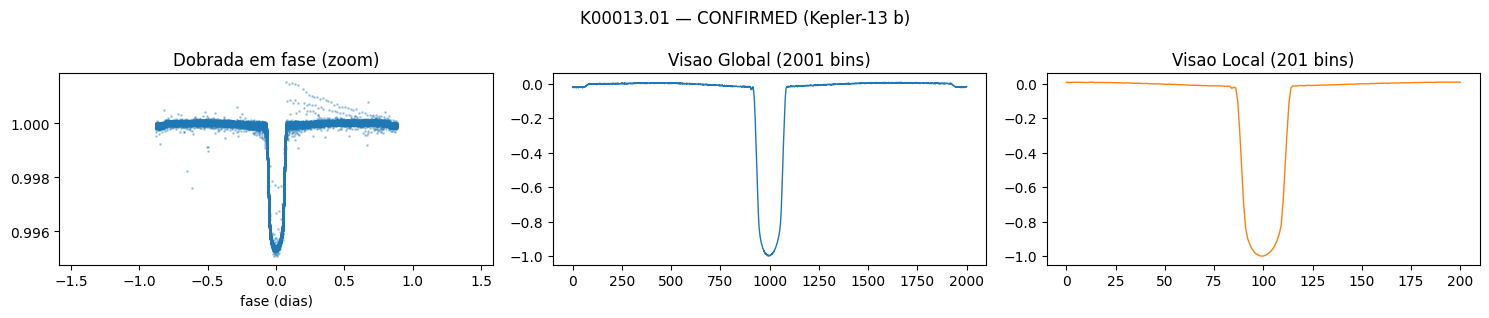

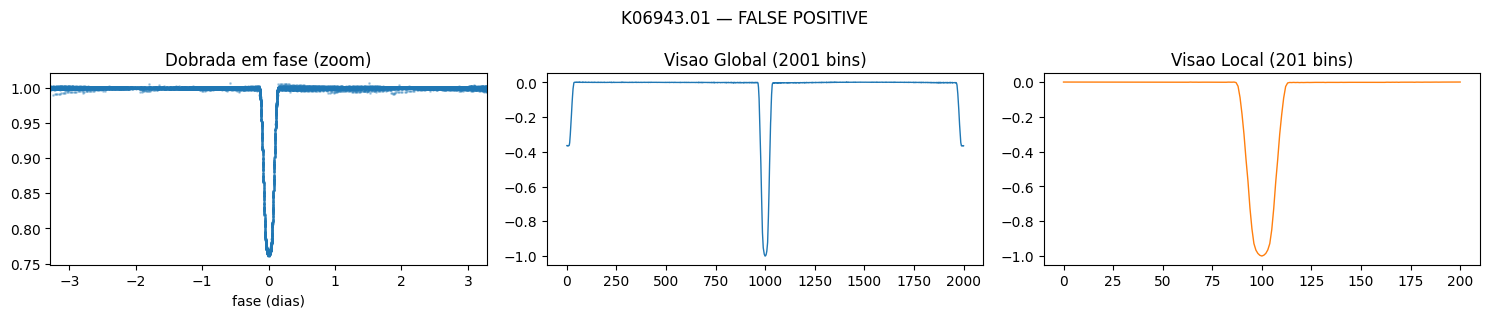

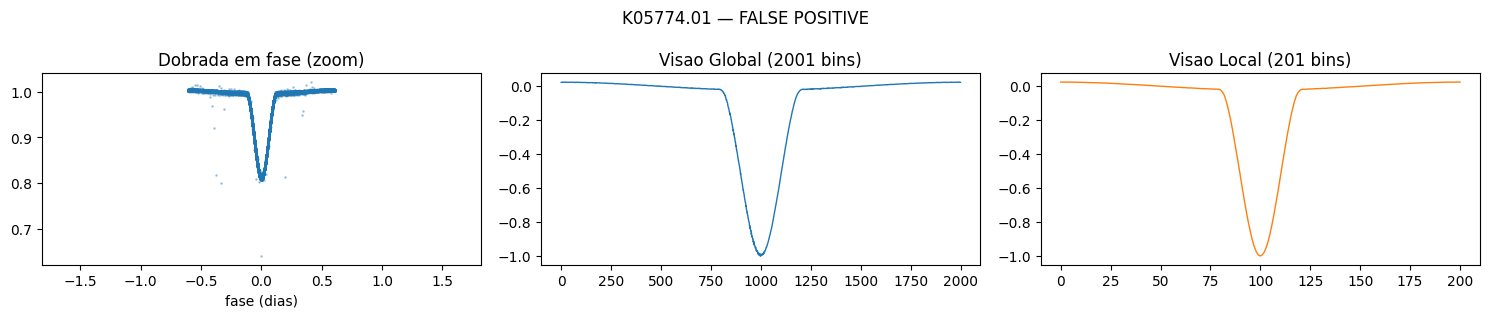

In [8]:
for r in resultados:
    row = r['row']
    titulo = f"{row.kepoi_name} — {row.koi_disposition}"
    if isinstance(row.kepler_name, str):
        titulo += f" ({row.kepler_name})"

    fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
    fig.suptitle(titulo, fontsize=12)

    ax[0].scatter(r['phase'], r['flux'], s=1, alpha=0.3)
    ax[0].set_xlim(-r['half_local'] * 3, r['half_local'] * 3)
    ax[0].set_title('Dobrada em fase (zoom)')
    ax[0].set_xlabel('fase (dias)')

    ax[1].plot(r['global_view'], lw=1)
    ax[1].set_title(f'Visao Global ({GLOBAL_BINS} bins)')

    ax[2].plot(r['local_view'], lw=1, color='C1')
    ax[2].set_title(f'Visao Local ({LOCAL_BINS} bins)')

    plt.tight_layout()
    plt.show()

## 7. O que conferir

- o trânsito aparece centrado na Visão Local dos planetas confirmados;
- o mínimo de todas as visões fica em −1;
- a Visão Global tem 2.001 bins, qualquer que seja o período;
- o achatamento remove as tendências lentas sem deformar o trânsito;
- nenhum alvo falhou no download.

## Próximo passo

O notebook 03 aplica o mesmo processamento aos 6.695 KOIs, faz a partição por estrela e aplica o SMOTE ao treino.